## Import required Libraries


In [1]:
import pandas as pd
import numpy as np
import duckdb

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from pathlib import Path

### Define dataset paths

In [2]:
DATA_DIR = Path("../dataset")
CLEAN_DIR = Path("../outputs/cleaned_data")
INTEGRATED_DIR = Path("../outputs/integrated_data")

output_path = (INTEGRATED_DIR / "integrated_prior.parquet").resolve().as_posix()

train_path = (CLEAN_DIR / "order_products__train.csv").resolve().as_posix()

print("Prior dataset exists:", Path(output_path).exists())
print("Train dataset exists:", Path(train_path).exists())

Prior dataset exists: True
Train dataset exists: True


checking duckDb connection

In [3]:
con = duckdb.connect()

train_preview = con.execute(f"""
    SELECT *
    FROM read_csv_auto('{train_path}')
    LIMIT 5
""").df()

display(train_preview)

,order_id,product_id,add_to_cart_order,reordered
0,1,49302,1,1
1,1,11109,2,1
2,1,10246,3,0
3,1,49683,4,0
4,1,43633,5,1


In [4]:
train_summary = con.execute(f"""
    SELECT
        COUNT(*) AS total_records,
        COUNT(DISTINCT order_id) AS total_orders,
        COUNT(DISTINCT product_id) AS unique_products
    FROM read_csv_auto('{train_path}')
""").df()

display(train_summary)

,total_records,total_orders,unique_products
0,1384617,131209,39123


train dataset contains order_id, but not user_id.
we need to connect it with orders.csv 


In [5]:
train_orders = con.execute(f"""
    SELECT
        t.order_id,
        o.user_id,
        t.product_id,
        t.reordered
    FROM read_csv_auto('{train_path}') t
    INNER JOIN read_csv_auto('{(CLEAN_DIR / "orders.csv").resolve().as_posix()}') o
        ON t.order_id = o.order_id
    LIMIT 10
""").df()

display(train_orders)

,order_id,user_id,product_id,reordered
0,1187899,1,46149,1
1,1492625,2,21329,0
2,2196797,5,21616,1
3,525192,7,45066,1
4,880375,8,2846,0
5,1094988,9,30967,1
6,1822501,10,10177,0
7,1827621,13,19934,1
8,2316178,14,42284,0
9,2180313,17,4374,0


checking historical product purchase for each customer this helps us to understand the historical behaviour our model needs to learn


In [6]:
historical_features = con.execute(f"""
    SELECT
        user_id,
        product_id,
        COUNT(*) AS product_purchase_count,
        SUM(reordered) AS previous_reorders,
        AVG(reordered) AS product_reorder_ratio
    FROM read_parquet('{output_path}')
    GROUP BY user_id, product_id
    LIMIT 10
""").df()

display(historical_features)

,user_id,product_id,product_purchase_count,previous_reorders,product_reorder_ratio
0,135442,3464,10,9.0,0.900000
1,152610,29471,1,0.0,0.000000
2,83009,41540,9,8.0,0.888889
3,98256,25256,19,18.0,0.947368
4,94330,276,1,0.0,0.000000
5,127522,42736,4,3.0,0.750000
6,34016,47209,12,11.0,0.916667
7,66984,37110,3,2.0,0.666667
8,5738,46654,14,13.0,0.928571
9,186444,22867,4,3.0,0.750000


### Generate historical features for all customers

In [7]:
features_path = (
    INTEGRATED_DIR / "customer_product_features.parquet"
).resolve().as_posix()

con.execute(f"""
    COPY (
        SELECT
            user_id,
            product_id,
            COUNT(*) AS product_purchase_count,
            SUM(reordered) AS previous_reorders,
            AVG(reordered) AS product_reorder_ratio
        FROM read_parquet('{output_path}')
        GROUP BY user_id, product_id
    )
    TO '{features_path}'
    (FORMAT PARQUET, COMPRESSION ZSTD)
""")

print("Historical features created successfully!")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Historical features created successfully!


In [9]:
#verifying the generated file
feature_summary = con.execute(f"""
    SELECT
        COUNT(*) AS total_customer_product_pairs,
        COUNT(DISTINCT user_id) AS total_customers,
        COUNT(DISTINCT product_id) AS total_products
    FROM read_parquet('{features_path}')
""").df()

display(feature_summary)

,total_customer_product_pairs,total_customers,total_products
0,13307953,206209,49677


### Generate target labels

identify which historical customer-product combinations appear in the customer's train order.

Our logic:
- If a customer-product pair exists in the train order → target = 1.
- If it does not exist → target = 0.

In [ ]:
positive_path = (
    INTEGRATED_DIR / "positive_examples.parquet"
).resolve().as_posix()

con.execute(f"""
    COPY (
        SELECT
            h.user_id,
            h.product_id,
            h.product_purchase_count,
            h.previous_reorders,
            h.product_reorder_ratio,
            1 AS target
        FROM read_parquet('{features_path}') h
        INNER JOIN (
            SELECT DISTINCT
                o.user_id,
                t.product_id
            FROM read_csv_auto('{train_path}') t
            INNER JOIN read_csv_auto(
                '{(CLEAN_DIR / "orders.csv").resolve().as_posix()}'
            ) o
                ON t.order_id = o.order_id
        ) target_data
            ON h.user_id = target_data.user_id
            AND h.product_id = target_data.product_id
    )
    TO '{positive_path}'
    (FORMAT PARQUET, COMPRESSION ZSTD)
""")

print("Positive examples created!")


#We connected the train orders with orders.csv to get user_id.
#We selected distinct customer-product pairs purchased in the train order.
#We matched those pairs against historical customer-product features.
#We assigned target = 1.

Positive examples created!


### Generate negative examples

approach:
- Positive: Customer purchased the product in their train order.
- Negative: Customer purchased the product in their previous orders, but did not purchase it in their train order.

In [11]:
negative_path = (
    INTEGRATED_DIR / "negative_examples.parquet"
).resolve().as_posix()

con.execute(f"""
    COPY (
        SELECT
            h.user_id,
            h.product_id,
            h.product_purchase_count,
            h.previous_reorders,
            h.product_reorder_ratio,
            0 AS target
        FROM read_parquet('{features_path}') h
        LEFT JOIN (
            SELECT DISTINCT
                o.user_id,
                t.product_id
            FROM read_csv_auto('{train_path}') t
            INNER JOIN read_csv_auto(
                '{(CLEAN_DIR / "orders.csv").resolve().as_posix()}'
            ) o
                ON t.order_id = o.order_id
        ) target_data
            ON h.user_id = target_data.user_id
            AND h.product_id = target_data.product_id
        WHERE target_data.user_id IS NULL
    )
    TO '{negative_path}'
    (FORMAT PARQUET, COMPRESSION ZSTD)
""")

print("Negative examples created!")

Negative examples created!


checking how many positive and negative combination we have


In [12]:
class_summary = con.execute(f"""
    SELECT
        target,
        COUNT(*) AS total_records
    FROM (
        SELECT * FROM read_parquet('{positive_path}')
        UNION ALL
        SELECT * FROM read_parquet('{negative_path}')
    )
    GROUP BY target
    ORDER BY target
""").df()

display(class_summary)

,target,total_records
0,0,12479129
1,1,828824


## Combine positive and negative examples

In [13]:
final_dataset_path = (
    INTEGRATED_DIR / "supervised_learning_dataset.parquet"
).resolve().as_posix()

con.execute(f"""
    COPY (
        SELECT * FROM read_parquet('{positive_path}')
        UNION ALL
        SELECT * FROM read_parquet('{negative_path}')
    )
    TO '{final_dataset_path}'
    (FORMAT PARQUET, COMPRESSION ZSTD)
""")

print("Final supervised learning dataset created!")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Final supervised learning dataset created!


verify the dataset

In [14]:
final_summary = con.execute(f"""
    SELECT
        COUNT(*) AS total_records,
        COUNT(DISTINCT user_id) AS total_customers,
        COUNT(DISTINCT product_id) AS unique_products,
        SUM(CASE WHEN target = 1 THEN 1 ELSE 0 END) AS positive_records,
        SUM(CASE WHEN target = 0 THEN 1 ELSE 0 END) AS negative_records
    FROM read_parquet('{final_dataset_path}')
""").df()

display(final_summary)

,total_records,total_customers,unique_products,positive_records,negative_records
0,13307953,206209,49677,828824.0,12479129.0


In [15]:
final_preview = con.execute(f"""
    SELECT *
    FROM read_parquet('{final_dataset_path}')
    LIMIT 5
""").df()

display(final_preview)

,user_id,product_id,product_purchase_count,previous_reorders,product_reorder_ratio,target
0,55039,4932,14,13.0,0.928571,1
1,97258,11090,16,15.0,0.937500,1
2,95594,48953,10,9.0,0.900000,1
3,183234,21949,2,1.0,0.500000,1
4,29863,36011,9,8.0,0.888889,1


### Add customer-level features

we know how frequently a customer buys a particular product.

But we don't yet know much about the customer's overall purchasing behaviour.

total_previous_orders :	Total number of previous orders placed by the customer

avg_basket_size	: Average number of products in each previous order

In [18]:
customer_features_path = (
    INTEGRATED_DIR / "customer_features.parquet"
).resolve().as_posix()

con.execute(f"""
    COPY (
        WITH order_sizes AS (
            SELECT
                user_id,
                order_id,
                COUNT(*) AS basket_size
            FROM read_parquet('{output_path}')
            GROUP BY user_id, order_id
        )
        SELECT
            user_id,
            COUNT(*) AS total_previous_orders,
            AVG(basket_size) AS avg_basket_size
        FROM order_sizes
        GROUP BY user_id
    )
    TO '{customer_features_path}'
    (FORMAT PARQUET, COMPRESSION ZSTD)
""")

print("Customer-level features created!")

#First, we calculate the number of products in each historical order.

#Then, we calculate how many previous orders each customer placed.

#Finally, we calculate their average basket size.

Customer-level features created!


In [17]:
customer_preview = con.execute(f"""
    SELECT *
    FROM read_parquet('{customer_features_path}')
    LIMIT 10
""").df()

display(customer_preview)

,user_id,total_previous_orders,avg_basket_size
0,88495,57,20.807018
1,88619,33,6.606061
2,97280,16,3.750000
3,19326,99,5.898990
4,20220,8,9.875000
5,203834,53,8.000000
6,27131,11,14.181818
7,134188,8,15.750000
8,175501,12,22.666667
9,62623,17,25.705882


### Combine all features

In [19]:
enriched_dataset_path = (
    INTEGRATED_DIR / "supervised_learning_enriched.parquet"
).resolve().as_posix()

con.execute(f"""
    COPY (
        SELECT
            d.user_id,
            d.product_id,
            d.product_purchase_count,
            d.previous_reorders,
            d.product_reorder_ratio,
            c.total_previous_orders,
            c.avg_basket_size,
            d.target
        FROM read_parquet('{final_dataset_path}') d
        LEFT JOIN read_parquet('{customer_features_path}') c
            ON d.user_id = c.user_id
    )
    TO '{enriched_dataset_path}'
    (FORMAT PARQUET, COMPRESSION ZSTD)
""")

print("Feature integration completed!")

Feature integration completed!


In [20]:
enriched_summary = con.execute(f"""
    SELECT
        COUNT(*) AS total_records,
        COUNT(*) FILTER (
            WHERE total_previous_orders IS NULL
        ) AS missing_customer_features
    FROM read_parquet('{enriched_dataset_path}')
""").df()

display(enriched_summary)

,total_records,missing_customer_features
0,13307953,0


In [21]:
import psutil

available_ram = psutil.virtual_memory().available / (1024 ** 3)

print(f"Available RAM: {available_ram:.2f} GB")

Available RAM: 0.87 GB


### Create a stratified sample using DuckDB

In [28]:
sample_path = (
    INTEGRATED_DIR / "supervised_learning_sample.parquet"
).resolve().as_posix()

con.execute(f"""
    COPY (
        SELECT
            user_id,
            product_id,
            product_purchase_count,
            previous_reorders,
            product_reorder_ratio,
            total_previous_orders,
            avg_basket_size,
            target
        FROM (
            SELECT
                *,
                ROW_NUMBER() OVER (
                    PARTITION BY target
                    ORDER BY random_value
                ) AS rn
            FROM (
                SELECT
                    *,
                    random() AS random_value
                FROM read_parquet('{enriched_dataset_path}')
            )
        )
        WHERE
            (target = 0 AND rn <= 466000)
            OR
            (target = 1 AND rn <= 34000)
    )
    TO '{sample_path}'
    (FORMAT PARQUET, COMPRESSION ZSTD)
""")

print("Stratified sample created!")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Stratified sample created!


In [24]:
sample_summary = con.execute(f"""
    SELECT
        target,
        COUNT(*) AS total_records
    FROM read_parquet('{sample_path}')
    GROUP BY target
    ORDER BY target
""").df()

display(sample_summary)

,target,total_records
0,0,466000
1,1,34000


# TRAINING MODEL 

## Load and inspect the sample

In [30]:
df = pd.read_parquet(sample_path)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (500000, 8)


,user_id,product_id,product_purchase_count,previous_reorders,product_reorder_ratio,total_previous_orders,avg_basket_size,target
0,63507,20955,1,0.0,0.000000,63,9.063492,0
1,53481,21616,5,4.0,0.800000,12,16.500000,0
2,160310,17123,1,0.0,0.000000,65,18.569231,0
3,140626,26939,1,0.0,0.000000,34,5.911765,0
4,134008,28289,3,2.0,0.666667,19,11.052632,0


### Separate features (X) and target (y)

In [31]:
feature_columns = [
    "product_purchase_count",
    "previous_reorders",
    "product_reorder_ratio",
    "total_previous_orders",
    "avg_basket_size"
]

X = df[feature_columns]
y = df["target"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (500000, 5)
Target shape: (500000,)


### Split the dataset into training and testing sets

In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (400000, 5)
Testing features: (100000, 5)

Training target distribution:
target
0    372800
1     27200
Name: count, dtype: int64

Testing target distribution:
target
0    93200
1     6800
Name: count, dtype: int64


## CART Decision Tree Classifier

Create the CART model

In [34]:
dt_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=12,
    class_weight="balanced",
    random_state=42
)

### Train the model


In [35]:
dt_model.fit(X_train, y_train)

print("Decision Tree model training completed!")

Decision Tree model training completed!


### Make predictions

In [36]:
y_pred_dt = dt_model.predict(X_test)

print("Predictions completed!")
print("First 10 predictions:", y_pred_dt[:10])

Predictions completed!
First 10 predictions: [0 0 0 1 0 0 0 0 1 0]


In [37]:
accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt)
recall_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)

print("Decision Tree Performance")
print("-------------------------")
print("Accuracy :", round(accuracy_dt, 4))
print("Precision:", round(precision_dt, 4))
print("Recall   :", round(recall_dt, 4))
print("F1 Score :", round(f1_dt, 4))

Decision Tree Performance
-------------------------
Accuracy : 0.7154
Precision: 0.1463
Recall   : 0.659
F1 Score : 0.2395


Generate the confusion matrix

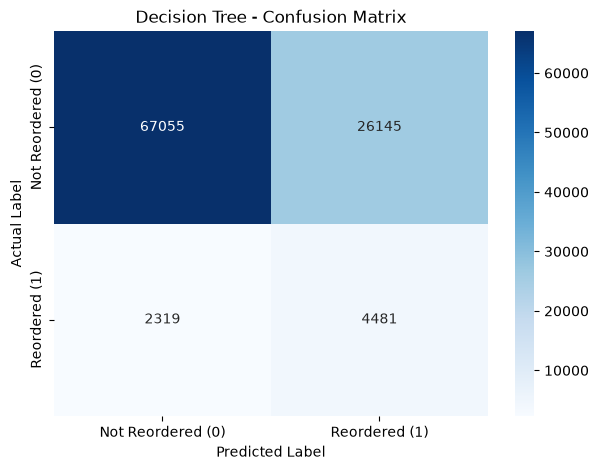

In [50]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Reordered (0)", "Reordered (1)"],
    yticklabels=["Not Reordered (0)", "Reordered (1)"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Decision Tree - Confusion Matrix")

plt.show()

In [40]:
dt_results = {
    "Model": "Decision Tree (CART)",
    "Accuracy": accuracy_dt,
    "Precision": precision_dt,
    "Recall": recall_dt,
    "F1 Score": f1_dt
}

print(dt_results)

{'Model': 'Decision Tree (CART)', 'Accuracy': 0.71536, 'Precision': 0.14631358976033434, 'Recall': 0.6589705882352941, 'F1 Score': 0.23945919948698766}


## Create the Random Forest model

In [41]:
rf_model = RandomForestClassifier(
    n_estimators=50,
    criterion="gini",
    max_depth=12,
    class_weight="balanced",
    random_state=42,
    n_jobs=1
)

### Train the Random Forest

In [42]:
rf_model.fit(X_train, y_train)

print("Random Forest model training completed!")

Random Forest model training completed!


### Make Random Forest predictions

In [43]:
y_pred_rf = rf_model.predict(X_test)

print("Random Forest predictions completed!")
print("First 10 predictions:", y_pred_rf[:10])

Random Forest predictions completed!
First 10 predictions: [0 0 0 0 0 0 0 0 1 0]


### Evaluate Random Forest

In [44]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

print("Random Forest Performance")
print("-------------------------")
print("Accuracy :", round(accuracy_rf, 4))
print("Precision:", round(precision_rf, 4))
print("Recall   :", round(recall_rf, 4))
print("F1 Score :", round(f1_rf, 4))

Random Forest Performance
-------------------------
Accuracy : 0.7315
Precision: 0.1535
Recall   : 0.6534
F1 Score : 0.2487


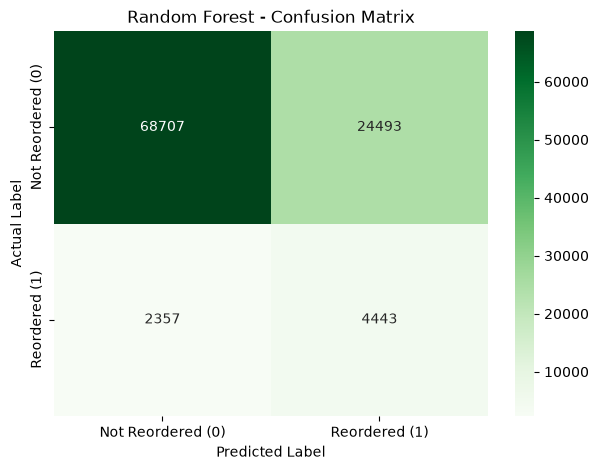

In [51]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Not Reordered (0)", "Reordered (1)"],
    yticklabels=["Not Reordered (0)", "Reordered (1)"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Random Forest - Confusion Matrix")

plt.show()

In [45]:
rf_results = {
    "Model": "Random Forest",
    "Accuracy": accuracy_rf,
    "Precision": precision_rf,
    "Recall": recall_rf,
    "F1 Score": f1_rf
}

print(rf_results)

{'Model': 'Random Forest', 'Accuracy': 0.7315, 'Precision': 0.15354575615150678, 'Recall': 0.6533823529411765, 'F1 Score': 0.24865681665547348}


In [46]:
comparison_df = pd.DataFrame([
    dt_results,
    rf_results
])

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree (CART),0.71536,0.146314,0.658971,0.239459
1,Random Forest,0.73150,0.153546,0.653382,0.248657


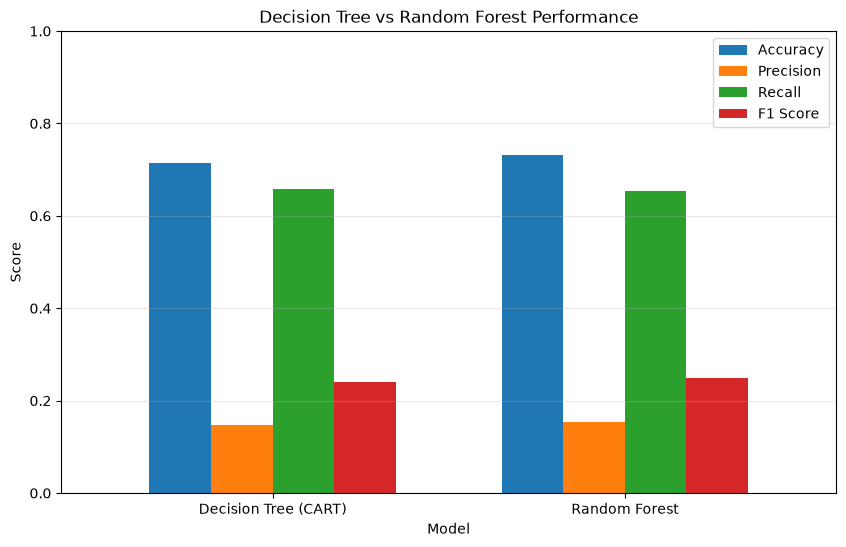

In [47]:
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

comparison_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6),
    width=0.7
)

plt.title("Decision Tree vs Random Forest Performance")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc="upper right")
plt.grid(axis="y", alpha=0.3)

plt.show()